In [1]:
import pandas as pd
from functools import reduce
import numpy as np  

In [2]:
#Wczytanie danych
SNK=pd.read_csv("Dane/SNK_d.csv")
SNK["Data"] = pd.to_datetime(SNK["Data"])
SNK = SNK.sort_values("Data")
SNK = SNK[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_SNK"})

SNK = SNK.sort_values("Data").reset_index(drop=True)
SNK = SNK[(SNK["Data"] >= "2015-01-01") & (SNK["Data"] <= "2019-12-31")]
SNK = SNK.reset_index(drop=True)

SNK

,Data,Close_SNK
0,2015-01-02,29.5689
1,2015-01-05,29.3951
2,2015-01-07,29.5562
3,2015-01-08,29.5689
4,2015-01-09,29.2100
...,...,...
1241,2019-12-19,13.5073
1242,2019-12-20,13.4311
1243,2019-12-23,14.4994
1244,2019-12-27,14.5756


In [3]:
SNK['Log_Return'] = np.log(SNK['Close_SNK'] / SNK['Close_SNK'].shift(1))

SNK

,Data,Close_SNK,Log_Return
0,2015-01-02,29.5689,NaN
1,2015-01-05,29.3951,-0.005895
2,2015-01-07,29.5562,0.005466
3,2015-01-08,29.5689,0.000430
4,2015-01-09,29.2100,-0.012212
...,...,...,...
1241,2019-12-19,13.5073,-0.014012
1242,2019-12-20,13.4311,-0.005657
1243,2019-12-23,14.4994,0.076534
1244,2019-12-27,14.5756,0.005242


In [4]:
SNK['Close_SNK'].describe()

count    1246.000000
mean       30.403450
std         9.051812
min        13.431100
25%        20.878800
50%        33.035150
75%        38.212200
max        44.707600
Name: Close_SNK, dtype: float64

In [5]:
SNK['Log_Return'].describe()

count    1245.000000
mean       -0.000560
std         0.019388
min        -0.117156
25%        -0.009562
50%         0.000000
75%         0.009065
max         0.122497
Name: Log_Return, dtype: float64

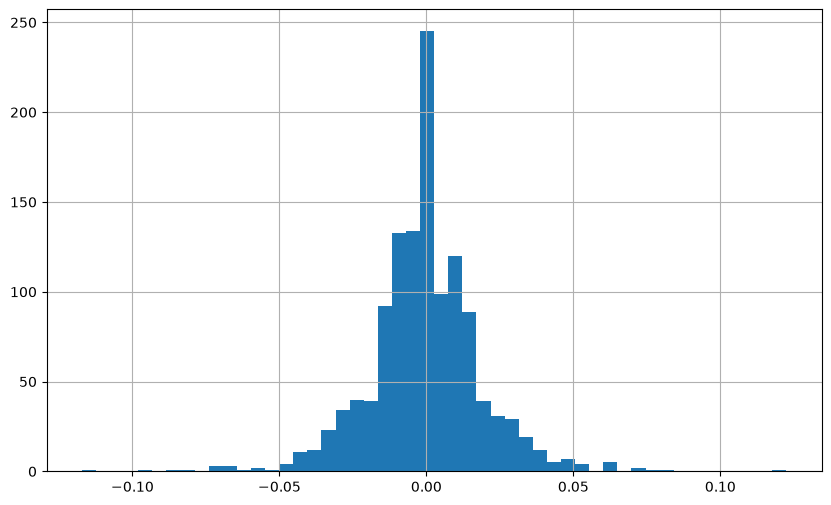

In [6]:
hist_SNK = SNK['Log_Return'].hist(bins=50, figsize=(10, 6))